In [79]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

train_data = pd.read_csv("../data/ai_human_content_detection_dataset.csv")
train_data.head()

,text_content,content_type,word_count,character_count,sentence_count,lexical_diversity,avg_sentence_length,avg_word_length,punctuation_ratio,flesch_reading_ease,gunning_fog_index,grammar_errors,passive_voice_ratio,predictability_score,burstiness,sentiment_score,label
0,Score each cause. Quality throughout beautiful...,academic_paper,288,1927,54,0.9514,5.33,5.69,0.0280,53.08,7.41,1,0.1041,105.86,0.5531,0.2034,1
1,Board its rock. Job worker break tonight coupl...,essay,253,1719,45,0.9723,5.62,5.80,0.0262,50.32,8.10,6,0.2045,100.29,0.5643,0.4854,1
2,Way debate decision produce. Dream necessary c...,academic_paper,420,2849,75,0.9071,5.60,5.79,0.0263,46.86,7.86,5,0.2308,96.88,0.4979,-0.2369,1
3,Story turn because such during open model. Tha...,creative_writing,196,1310,34,0.9592,5.76,5.69,0.0260,53.80,7.00,2,0.1912,88.79,0.6241,NaN,1
4,Place specific as simply leader fall analysis....,news_article,160,1115,28,0.9688,5.71,5.97,0.0251,44.53,8.29,0,0.1318,26.15,0.2894,NaN,1


# Preprocess the Data

In [80]:
# Fill empty data 

# loop through each column and fill empty data with the median (imputation) 
for column in train_data.columns:
    if train_data[column].isnull().sum() > 0:
        median = train_data[column].median()
        train_data[column] = train_data[column].fillna(median)


# Check for any remaining missing values
train_data.isnull().sum()

# Get your truth variable
y = train_data["label"]


# Remove label from the training set and the text content(for now if we want to use it later for future features)
train_data = train_data.drop(columns=['label'])
train_data = train_data.drop(columns=['text_content'])

train_data.info()





<class 'pandas.DataFrame'>
RangeIndex: 1367 entries, 0 to 1366
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   content_type          1367 non-null   str    
 1   word_count            1367 non-null   int64  
 2   character_count       1367 non-null   int64  
 3   sentence_count        1367 non-null   int64  
 4   lexical_diversity     1367 non-null   float64
 5   avg_sentence_length   1367 non-null   float64
 6   avg_word_length       1367 non-null   float64
 7   punctuation_ratio     1367 non-null   float64
 8   flesch_reading_ease   1367 non-null   float64
 9   gunning_fog_index     1367 non-null   float64
 10  grammar_errors        1367 non-null   int64  
 11  passive_voice_ratio   1367 non-null   float64
 12  predictability_score  1367 non-null   float64
 13  burstiness            1367 non-null   float64
 14  sentiment_score       1367 non-null   float64
dtypes: float64(10), int64(4), str(1)

# One-hot encode the categorical features

In [81]:
# separate numeric and categorical
categorical = ['content_type']
numeric = train_data.drop(columns=['content_type'])



# now get our training and testing split
X_train, X_test, y_train, y_test = train_test_split(
    train_data,
    y,
    test_size=0.2, # 80/20 split
    random_state=41,
    stratify=y
)


encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)


# Pass the categorical features to the encoder
X_train_cat = encoder.fit_transform(X_train[categorical])
X_test_cat = encoder.transform(X_test[categorical])


# Use scikit standard scaler
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[numeric.columns]) 
X_test_num = scaler.transform(X_test[numeric.columns])


# Combine the training data back together, and the test data back together
X_train_processed = np.hstack((X_train_num, X_train_cat))
X_test_processed = np.hstack((X_test_num, X_test_cat))

print(X_train_processed.shape)
print(X_test_processed.shape)



(1093, 22)
(274, 22)


# Plot the correlation

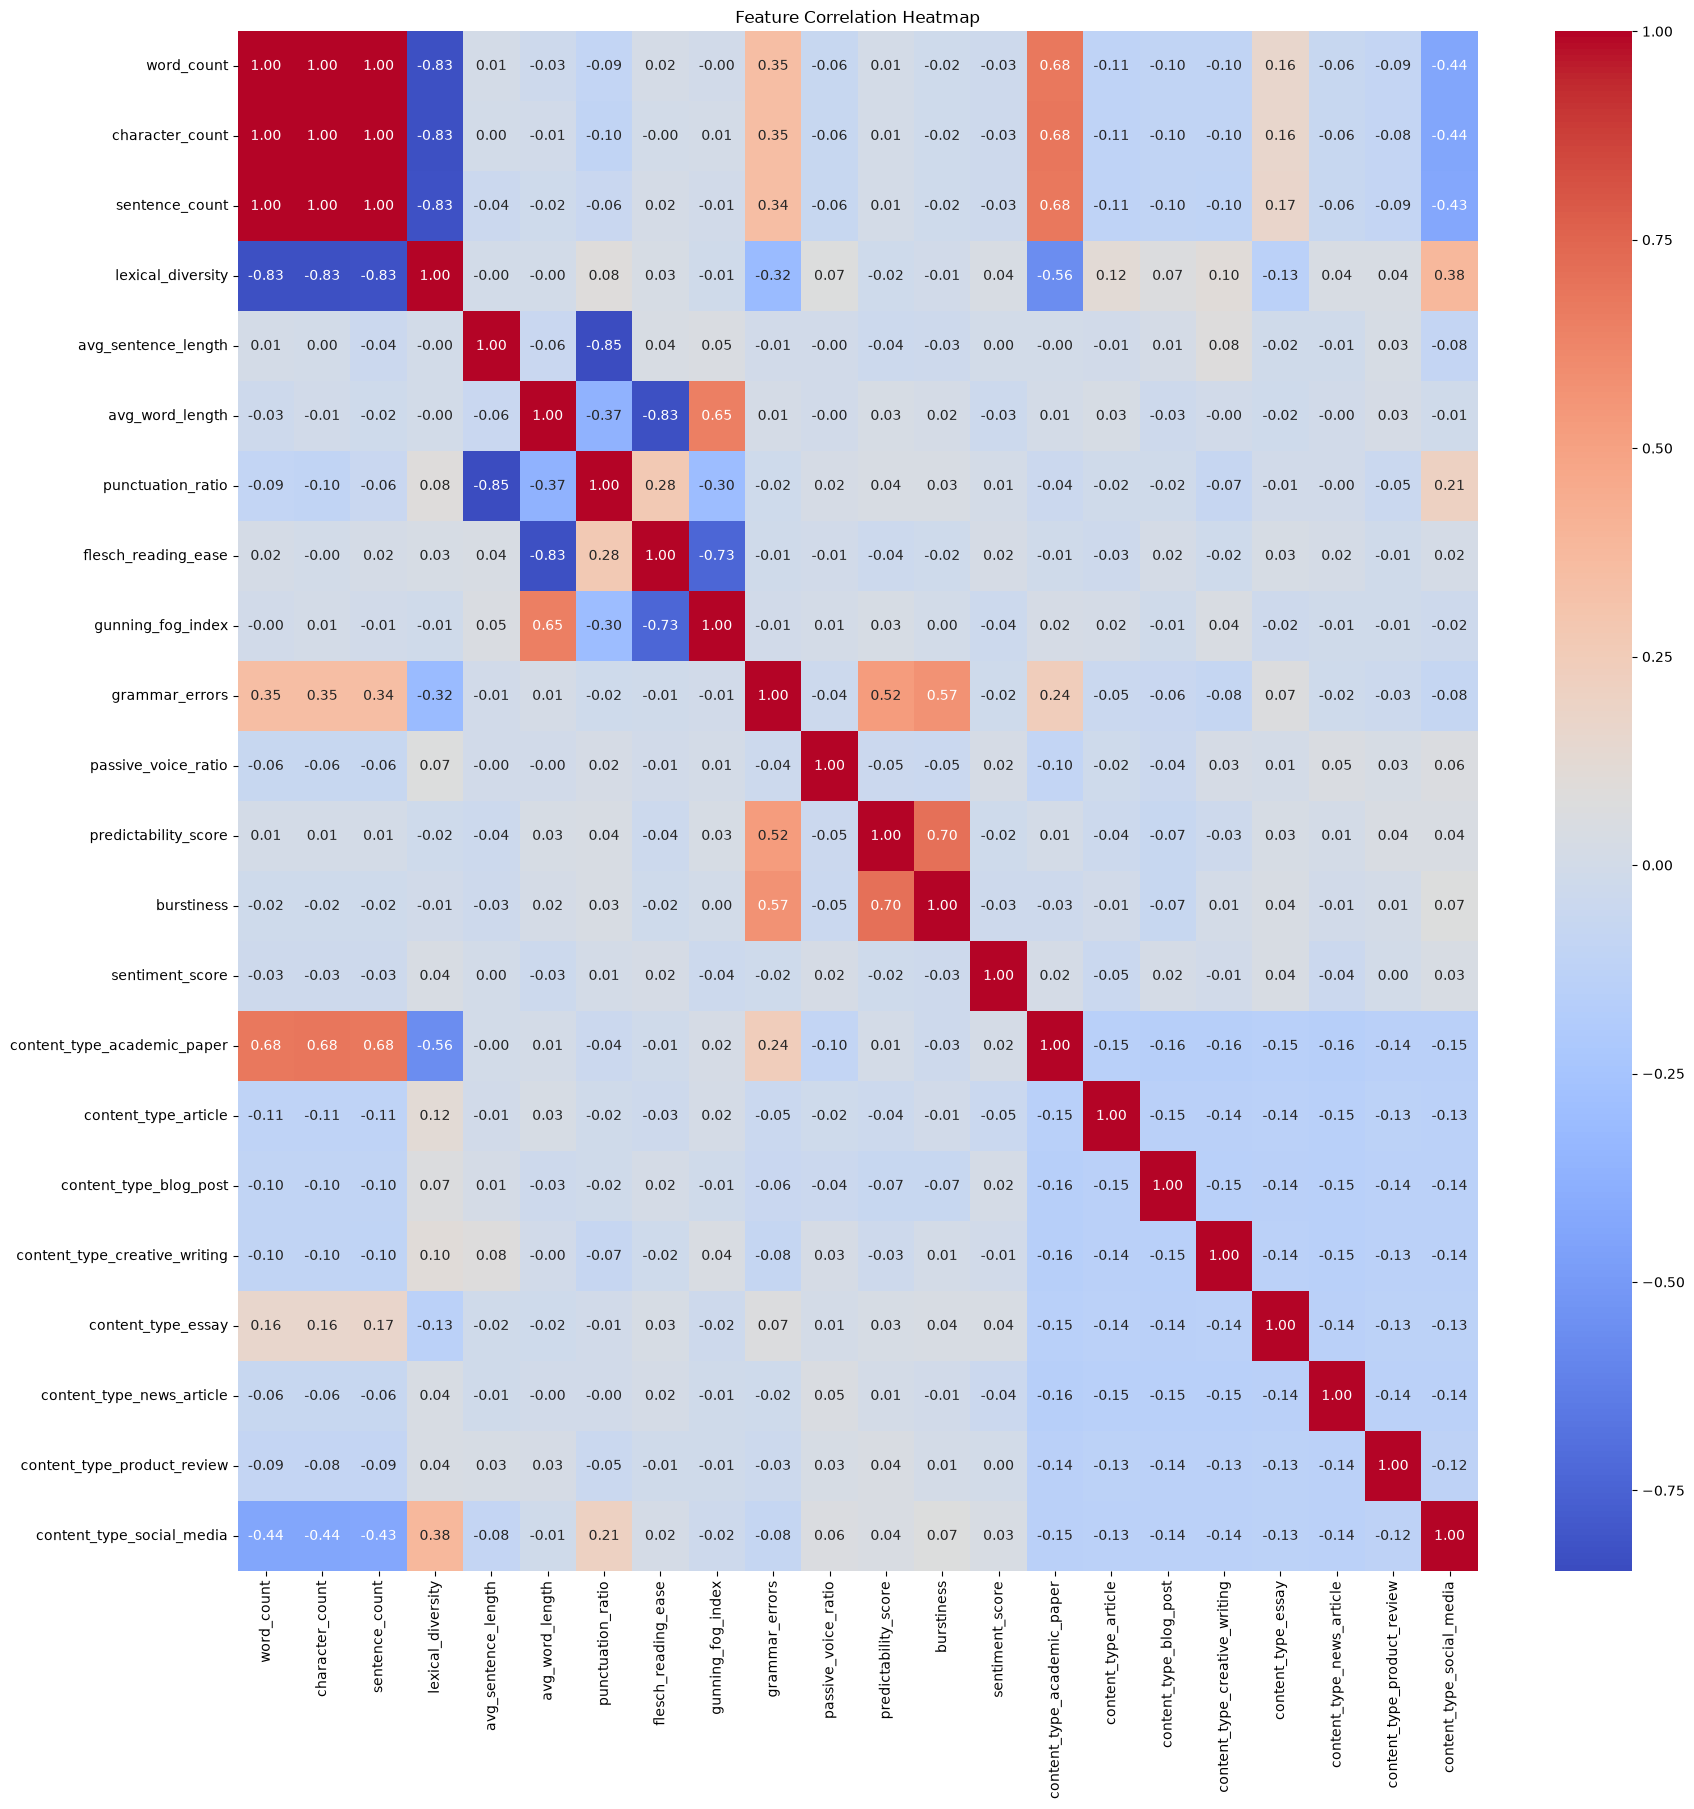

In [ ]:
cat_feature_names = encoder.get_feature_names_out(categorical)

total_feature_names = list(numeric.columns) + list(cat_feature_names)

# create a dataframe
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=total_feature_names
)

correlation = X_train_processed_df.corr()

plt.figure(figsize=(20,20))

# seaborn heatmap
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()




# Now create the sklearn logistic regression model

In [83]:
lr_model = LogisticRegression()
# Fit the training data
lr_model.fit(X_train_processed, y_train)

# predict
y_test_predict = lr_model.predict(X_test_processed)

# print accuracy of predictions
accuracy = accuracy_score(y_test, y_test_predict)

print(accuracy)

0.46715328467153283


# Get an AI likelihood score based on probability 

[46.62 47.48 37.89 58.31 45.7  45.01 48.85 44.61 49.57 37.6  41.62 46.07
 61.2  44.85 40.56 44.79 52.5  45.07 37.84 61.57 37.22 55.64 43.65 42.87
 47.37 52.47 56.58 43.37 37.5  54.64 58.71 51.71 46.39 36.74 48.83 53.39
 39.28 41.62 44.38 48.41 51.48 49.69 32.7  60.62 52.29 54.86 48.24 54.37
 57.95 47.6  42.19 33.38 54.08 47.74 38.95 62.37 57.71 52.99 52.91 55.11
 46.25 54.8  43.44 43.77 62.87 45.68 63.02 49.24 52.2  45.02 63.55 46.43
 47.85 54.8  52.97 47.23 44.44 51.66 52.09 60.26 64.31 45.45 57.1  46.99
 39.69 37.71 62.2  51.11 56.07 52.45 47.74 47.46 58.84 47.38 46.84 46.21
 51.58 43.6  54.82 63.45 48.58 51.92 56.2  60.07 48.81 38.25 58.39 58.42
 51.72 53.71 48.69 46.3  60.61 58.25 53.72 44.81 52.72 52.99 53.64 50.08
 54.75 58.84 54.42 47.76 35.61 61.05 50.93 61.89 47.46 60.72 53.07 55.19
 41.75 36.39 42.81 55.24 49.03 49.28 47.76 41.54 56.35 38.98 41.75 57.23
 57.29 61.82 62.36 47.66 46.87 53.7  41.45 54.29 49.76 56.14 60.01 49.11
 53.93 33.75 54.62 50.79 49.58 41.55 41.81 44.38 45

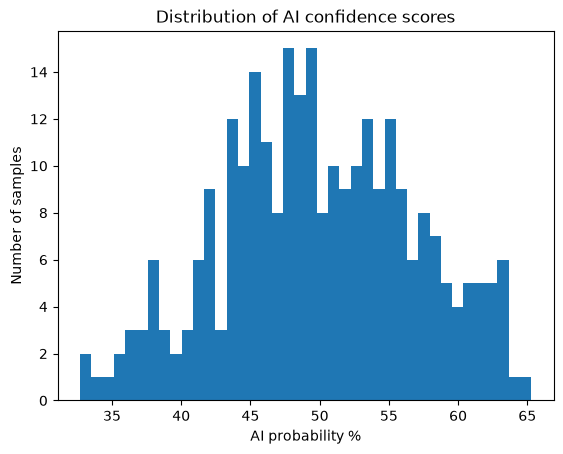

In [84]:

def get_ai_confidence(model, features):

    # sklearn has predict_proba() function to get probability of each class 
    probabilites = model.predict_proba(features)

    ai_class_index = list(model.classes_).index(1)

    # for every row in test 
    ai_probability = probabilites[:, ai_class_index] * 100

    # round to 2 decimal places
    return ai_probability.round(2)




confidence = get_ai_confidence(lr_model, X_test_processed)

# Each number in the confidence score array corresponds to the ai probability for each sample in test data
print(confidence)


# Plot to see the distribution better
plt.hist(confidence, bins=40)
plt.xlabel("AI probability %")
plt.ylabel("Number of samples")
plt.title("Distribution of AI confidence scores")
plt.show()